# SP-4 — Estatística espacial: Moran global e LISA

**Squad Inteligência · spike de 1 dia · Sprint 1**

**Pergunta:** a incidência de dengue nos bairros do Recife em 2024 está espacialmente agrupada? Onde estão os agrupamentos alto-alto (hotspots)?

**Aceite:** mapa LISA da incidência de 2024 + resumo de 1 página para o orientador.

**Dados:** painel bairro × SE (US14), casos de 2024; polígonos dos 94 bairros (`bairros_esig.geojson`).
**População:** placeholder opção A (US08 pendente). Sem denominador populacional, o LISA roda sobre casos; o padrão espacial é o mesmo que o de uma taxa com denominador constante.


In [1]:
%matplotlib inline
import sys
from pathlib import Path

for candidato in (Path.cwd(), Path.cwd() / "backend" / "notebooks"):
    if (candidato / "_comum.py").exists():
        sys.path.insert(0, str(candidato))
        break
else:
    raise RuntimeError("Rode o notebook em backend/notebooks ou na raiz do repo")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import _comum

_comum.SAIDAS_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
np.random.seed(42)
print("saídas em", _comum.SAIDAS_DIR)
import geopandas as gpd
import libpysal
import esda
from libpysal.weights import Queen, KNN
from matplotlib.patches import Patch


saídas em /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas


## 1. Unidade de análise e variável

Agregamos os casos de 2024 por bairro. Com população real, a variável seria **incidência por 100 mil**; com o placeholder, usamos **casos notificados** e rotulamos o mapa como proxy.

> **Por que o LISA é válido mesmo assim:** o Moran's I é uma razão de formas quadráticas e é invariante a uma multiplicação positiva constante dos valores. Com denominador constante, a classificação HH/LL/HL/LH e os p-valores permutacionais são idênticos aos da taxa. O que muda é a unidade de leitura.


In [2]:
painel = _comum.carregar_painel(anos=[2024])
casos = (
    painel.groupby("bairro_norm", as_index=False)["casos"].sum()
    .rename(columns={"casos": "casos_2024"})
)
casos["key"] = casos["bairro_norm"]

geo = _comum.carregar_geo()[["key", "EBAIRRNOME", "CDISTSANTPSAD", "area_km2", "geometry"]]
geo = geo.merge(casos[["key", "casos_2024"]], on="key", how="left")
pop = _comum.carregar_populacao()
geo = geo.merge(pop[["key", "populacao", "fonte"]], on="key", how="left")

usa_populacao_real = geo["populacao"].nunique() > 1
if usa_populacao_real:
    geo["valor"] = geo["casos_2024"] / geo["populacao"] * 100_000
    rotulo = "Incidência por 100 mil habitantes — 2024"
else:
    geo["valor"] = geo["casos_2024"]
    rotulo = "Casos notificados — 2024 (proxy de incidência; US08 pendente)"

print("bairros:", len(geo), "| casos sem match:", int(geo["casos_2024"].isna().sum()))
print("total de casos 2024:", int(geo["casos_2024"].sum()), "| fonte:", geo["fonte"].iloc[0])
print("variável do LISA:", rotulo)
display(geo.sort_values("casos_2024", ascending=False)[["EBAIRRNOME", "CDISTSANTPSAD", "casos_2024"]].head(10).reset_index(drop=True))

bairros: 94 | casos sem match: 0
total de casos 2024: 9716 | fonte: placeholder_opcao_A (US08 pendente)
variável do LISA: Casos notificados — 2024 (proxy de incidência; US08 pendente)


,EBAIRRNOME,CDISTSANTPSAD,casos_2024
0,IBURA,8,627.0
1,VARZEA,4,515.0
2,BOA VIAGEM,6,474.0
3,IPUTINGA,4,443.0
4,NOVA DESCOBERTA,7,401.0
5,COHAB,8,389.0
6,IMBIRIBEIRA,6,381.0
7,JARDIM SAO PAULO,5,293.0
8,AFOGADOS,5,243.0
9,AGUA FRIA,2,235.0


## 2. Matriz de vizinhança

Contiguidade **Queen** (compartilha borda ou vértice), linha-padronizada. Se houver ilhas, caímos para KNN com k=4 e registramos a decisão.


In [3]:
w = Queen.from_dataframe(geo, use_index=False)
if len(w.islands) > 0:
    print("Ilhas na contiguidade:", w.islands, "→ usando KNN k=4")
    w = KNN.from_dataframe(geo, k=4)
w.transform = "r"

print("n:", w.n, "| vizinhos médios:", round(float(np.mean(list(w.cardinalities.values()))), 2),
      "| ilhas:", len(w.islands))

n: 94 | vizinhos médios: 5.38 | ilhas: 0


## 3. Moran global

$I > 0$ indica agrupamento espacial (vizinhos parecidos); testamos com 999 permutações.


In [4]:
np.random.seed(42)
moran = esda.Moran(geo["valor"].values, w, permutations=999)

print(f"Moran's I = {moran.I:.4f}")
print(f"Esperado sob aleatoriedade = {moran.EI:.4f}")
print(f"z = {moran.z_sim:.3f} | p(permutações) = {moran.p_sim:.4f} | p(normal) = {moran.p_norm:.2e}")

resumo_moran = pd.DataFrame([{
    "variavel": rotulo, "I": moran.I, "EI": moran.EI, "z": moran.z_sim,
    "p_perm": moran.p_sim, "p_normal": moran.p_norm, "permutacoes": 999,
}])
resumo_moran.round(6).to_csv(_comum.SAIDAS_DIR / "sp4_moran_global.csv", index=False)
display(resumo_moran.round(6))

Moran's I = 0.2738
Esperado sob aleatoriedade = -0.0108
z = 4.886 | p(permutações) = 0.0010 | p(normal) = 6.96e-06


,variavel,I,EI,z,p_perm,p_normal,permutacoes
0,Casos notificados — 2024 (proxy de incidência;...,0.273805,-0.010753,4.88568,0.001,0.000007,999


## 4. LISA (Moran local)

Cada bairro recebe um quadrante e um p-valor permutacional. Só marcamos como cluster se `p_sim < 0,05`.


In [5]:
np.random.seed(42)
lisa = esda.Moran_Local(geo["valor"].values, w, permutations=999)

geo["p_sim"] = lisa.p_sim
geo["quadrante"] = lisa.q
geo["I_local"] = lisa.Is
geo["cluster"] = "ns"
for q, cat in [(1, "HH"), (2, "LH"), (3, "LL"), (4, "HL")]:
    geo.loc[(lisa.p_sim < 0.05) & (lisa.q == q), "cluster"] = cat

contagem = (
    geo["cluster"].value_counts()
    .reindex(["HH", "LH", "LL", "HL", "ns"]).fillna(0).astype(int)
    .to_frame("bairros")
)
contagem.index = [_comum.ROTULOS_LISA[i] for i in contagem.index]
display(contagem)
contagem.to_csv(_comum.SAIDAS_DIR / "sp4_contagem_lisa.csv")

,bairros
Alto-Alto (hotspot),10
Baixo-Alto (outlier),3
Baixo-Baixo (coldspot),2
Alto-Baixo (outlier),0
Não significativo,79


In [6]:
saida = geo[[
    "key", "EBAIRRNOME", "CDISTSANTPSAD", "casos_2024", "valor",
    "p_sim", "quadrante", "I_local", "cluster", "geometry",
]].copy()
saida["EBAIRRNOME"] = saida["EBAIRRNOME"].str.title()
saida.to_file(_comum.SAIDAS_DIR / "sp4_lisa_2024.geojson", driver="GeoJSON")
saida.drop(columns="geometry").to_csv(_comum.SAIDAS_DIR / "sp4_lisa_2024.csv", index=False)
print("GeoJSON:", _comum.SAIDAS_DIR / "sp4_lisa_2024.geojson")
print("tabela:", _comum.SAIDAS_DIR / "sp4_lisa_2024.csv")

GeoJSON: /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas/sp4_lisa_2024.geojson
tabela: /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas/sp4_lisa_2024.csv


## 5. Diagrama de Moran

figura salva em /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas/sp4_moran_scatter_2024.png


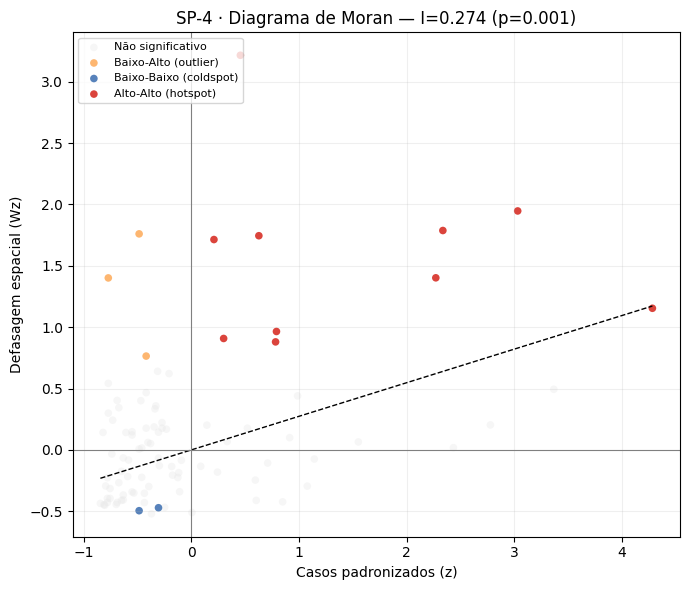

In [7]:
z = (geo["valor"] - geo["valor"].mean()) / geo["valor"].std(ddof=0)
lag = w.sparse.dot(z.values)

fig, ax = plt.subplots(figsize=(7, 6))
for cat in ["ns", "HL", "LH", "LL", "HH"]:
    m = (geo["cluster"] == cat).values
    if m.any():
        ax.scatter(z[m], lag[m], s=30, color=_comum.CORES_LISA[cat],
                   alpha=0.35 if cat == "ns" else 0.9, label=_comum.ROTULOS_LISA[cat],
                   edgecolor="none")
xs = np.linspace(z.min(), z.max(), 50)
ax.plot(xs, moran.I * xs, color="black", linestyle="--", linewidth=1)
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Casos padronizados (z)")
ax.set_ylabel("Defasagem espacial (Wz)")
ax.set_title(f"SP-4 · Diagrama de Moran — I={moran.I:.3f} (p={moran.p_sim:.3f})")
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.2)
fig.tight_layout()
caminho = _comum.salvar_figura(fig, "sp4_moran_scatter_2024.png")
print("figura salva em", caminho)
plt.show()

## 6. Mapa LISA de 2024

figura salva em /home/ariel/PULSO/PULSO-hackathon-aries/backend/notebooks/saidas/sp4_mapa_lisa_2024.png


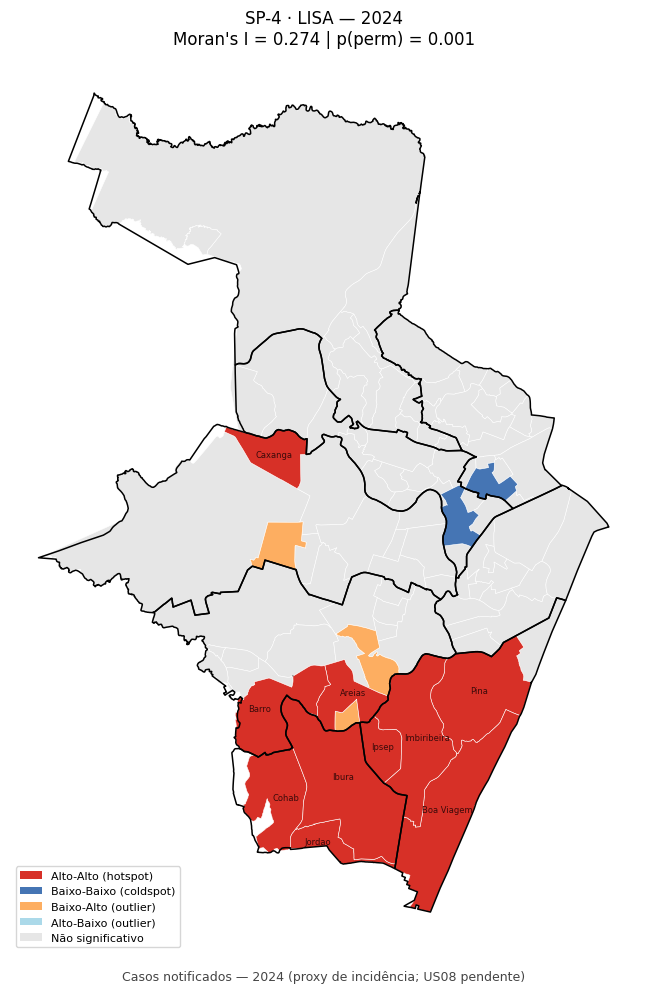

In [8]:
distritos = _comum.carregar_distritos().to_crs(geo.crs)

fig, ax = plt.subplots(figsize=(10, 10))
for cat in ["ns", "HL", "LH", "LL", "HH"]:
    m = geo["cluster"] == cat
    if m.any():
        geo[m].plot(ax=ax, color=_comum.CORES_LISA[cat], edgecolor="white", linewidth=0.4)

distritos.boundary.plot(ax=ax, color="black", linewidth=1.1)

for _, row in geo[geo["cluster"] == "HH"].iterrows():
    p = row.geometry.representative_point()
    ax.annotate(row["EBAIRRNOME"].title(), (p.x, p.y), fontsize=6, ha="center", color="#3b0a0a")

ax.set_title(f"SP-4 · LISA — 2024\nMoran's I = {moran.I:.3f} | p(perm) = {moran.p_sim:.3f}")
ax.text(0.5, -0.03, rotulo, transform=ax.transAxes, ha="center", fontsize=9, color="#444")
ax.axis("off")
legenda = [Patch(facecolor=_comum.CORES_LISA[c], label=_comum.ROTULOS_LISA[c]) for c in ["HH", "LL", "LH", "HL", "ns"]]
ax.legend(handles=legenda, loc="lower left", fontsize=8, frameon=True)
fig.tight_layout()
caminho = _comum.salvar_figura(fig, "sp4_mapa_lisa_2024.png")
print("figura salva em", caminho)
plt.show()

## 7. Onde estão os hotspots

In [9]:
hh = geo[geo["cluster"] == "HH"].copy()
hh["ds"] = "DS " + hh["CDISTSANTPSAD"].astype(str)
por_ds = hh.groupby("ds").size().sort_values(ascending=False).to_frame("bairros_HH")
display(por_ds)
por_ds.to_csv(_comum.SAIDAS_DIR / "sp4_hh_por_ds.csv")

print("\nBairros HH:", ", ".join(sorted(hh["EBAIRRNOME"].str.title())))
print("\nBairros LL:", ", ".join(sorted(geo.loc[geo["cluster"] == "LL", "EBAIRRNOME"].str.title())))

,bairros_HH
ds,
DS 6,4
DS 8,3
DS 5,2
DS 4,1



Bairros HH: Areias, Barro, Boa Viagem, Caxanga, Cohab, Ibura, Imbiribeira, Ipsep, Jordao, Pina

Bairros LL: Encruzilhada, Gracas


## 8. Leitura e limitações

- O Moran global mede agrupamento **médio**; o LISA localiza onde ele ocorre, mas cada bairro é testado separadamente (sem correção de múltiplas comparações nesta versão).
- Com população placeholder, bairros populosos aparecem com muitos casos por construção. **Boa Viagem** é o exemplo clássico: pode ser HH em casos e deixar de ser em incidência por 100 mil. Reexecutar com US08 antes de levar o mapa para a tela.
- Contagens pequenas tornam taxas instáveis; por isso o resultado é descritivo, não decisório.
- MAUP: o resultado depende da malha de bairros; não vale para setores censitários nem para indivíduos.
- A escolha Queen é uma decisão metodológica; KNN k=4 é a checagem de sensibilidade natural.
- Dados ecológicos: associação espacial não implica causalidade.


In [10]:
print("=== Resumo SP-4 ===")
print(f"Variável: {rotulo}")
print(f"Moran's I = {moran.I:.4f} | p(perm) = {moran.p_sim:.4f} | z = {moran.z_sim:.2f}")
print("Classificação LISA:", contagem["bairros"].to_dict())
print("Hotspots HH:", ", ".join(sorted(hh["EBAIRRNOME"].str.title())))
print("HH por DS:", por_ds["bairros_HH"].to_dict())

=== Resumo SP-4 ===
Variável: Casos notificados — 2024 (proxy de incidência; US08 pendente)
Moran's I = 0.2738 | p(perm) = 0.0010 | z = 4.89
Classificação LISA: {'Alto-Alto (hotspot)': 10, 'Baixo-Alto (outlier)': 3, 'Baixo-Baixo (coldspot)': 2, 'Alto-Baixo (outlier)': 0, 'Não significativo': 79}
Hotspots HH: Areias, Barro, Boa Viagem, Caxanga, Cohab, Ibura, Imbiribeira, Ipsep, Jordao, Pina
HH por DS: {'DS 6': 4, 'DS 8': 3, 'DS 5': 2, 'DS 4': 1}
